# Regression from a criterion to an estimate

An econometric estimator can be expressed as a scalar criterion plus its
first two derivatives. This example minimizes average squared error using
GALAHAD TRU and ARC, checks the solution against QR/SVD least squares, and
then uses the estimator interface for prediction and heteroskedasticity-robust
inference. All data are generated within the notebook.

For the complete design matrix $D$ and response $y$,
$$f(b)=\frac{\|Db-y\|^2}{2n},\quad
  g(b)=D^T(Db-y)/n,\quad H(b)=D^TD/n.$$

In [1]:
import os
# Notebook-process settings; importing the library never changes these.
os.environ.setdefault("OMP_CANCELLATION", "TRUE")
os.environ.setdefault("OMP_PROC_BIND", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

%matplotlib inline
thread_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(1001)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 9)
pd.set_option("display.max_columns", 10)
pd.options.display.float_format = "{:.5g}".format

In [2]:
from galahad_econometrics import Criterion, OLS, tru, arc, check_derivatives

n, p = 1600, 3
X = rng.normal(size=(n, p))
D = np.column_stack([np.ones(n), X])
beta = np.array([0.4, 0.8, -0.5, 0.25])
sigma = 0.3 + 0.4 * np.abs(X[:, 0])
y = D @ beta + sigma * rng.normal(size=n)

## Define the loss and exact derivatives

In [3]:
def objective(b):
    residual = D @ b - y
    return float(residual @ residual / (2 * n))

def gradient(b):
    return D.T @ (D @ b - y) / n

H = D.T @ D / n
criterion = Criterion(fun=objective, grad=gradient, hess=lambda b: H)
checks = check_derivatives(criterion, np.full(p + 1, 0.1))
assert max(checks.values()) < 1e-6
checks

{'gradient_error': 3.4869329645914604e-12,
 'hessian_error': 6.570054839727261e-11}

## Choose the optimizer

The criterion is unchanged between solvers. The wrapper infers the dimension
from `x0`, packs the Hessian, and manages native initialization and cleanup.
`success` combines the native stop with an independently recomputed gradient check.

In [4]:
solutions = {}
for name, module in [("TRU", tru), ("ARC", arc)]:
    result = module.solve(criterion, x0=np.zeros(p + 1), trace=True)
    assert result.success, result.message
    solutions[name] = result

closed_form = np.linalg.lstsq(D, y, rcond=None)[0]
comparison = pd.DataFrame({"truth": beta, "least squares": closed_form,
                           "TRU": solutions["TRU"].x, "ARC": solutions["ARC"].x},
                          index=["intercept", "x1", "x2", "x3"])
assert np.max(np.abs(solutions["TRU"].x - closed_form)) < 1e-7
assert np.max(np.abs(solutions["ARC"].x - closed_form)) < 1e-7
comparison

,truth,least squares,TRU,ARC
intercept,0.4,0.41431,0.41431,0.41431
x1,0.8,0.73697,0.73697,0.73697
x2,-0.5,-0.49015,-0.49015,-0.49015
x3,0.25,0.22214,0.22214,0.22214


## Add predictions and inference

`OLS(X, y)` adds an intercept; the handwritten criterion used the full design
`D`. The HC1 covariance is a sandwich with the finite-sample factor $n/(n-p)$,
where $p$ now denotes the number of estimated parameters including the intercept.
Truth-versus-estimate differences reflect sampling error. Differences from the
least-squares solution measure numerical error.

In [5]:
fit = OLS(X, y).fit(solver="tru", cov_type="HC1")
assert np.max(np.abs(fit.params - closed_form)) < 1e-7
print(fit.summary())
fit.predict(X[:5])

OLS | GALAHAD TRU
n=1600, parameters=4, success=True, native status=0
objective=0.22177239, optimality=8.62e-16, iterations=1
Inference: HC1, normal-approximation 95% intervals
     parameter       estimate     std. error          lower          upper
     intercept      0.4143068     0.01662407      0.3817242      0.4468894
            x1      0.7369652     0.02616827      0.6856763       0.788254
            x2     -0.4901501     0.01689843     -0.5232704     -0.4570298
            x3      0.2221423     0.01669103      0.1894285      0.2548561


array([0.92362755, 1.96930375, 0.73959388, 1.3152569 , 0.5731471 ])

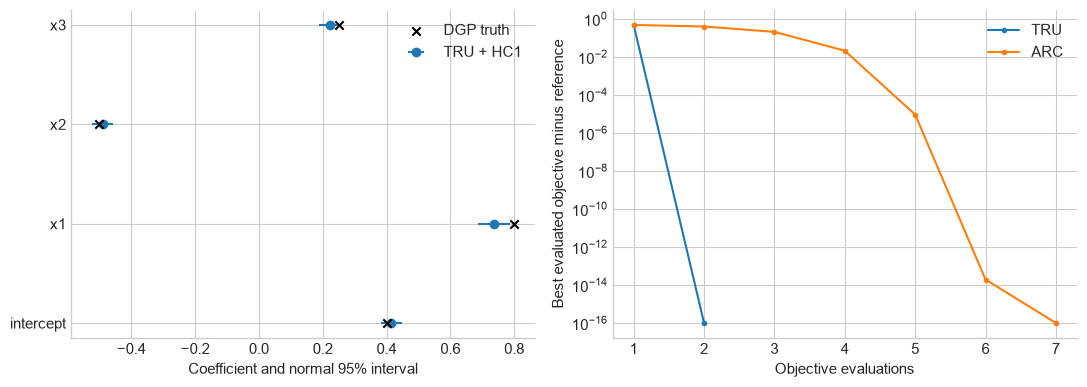

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
positions = np.arange(p + 1)
axes[0].errorbar(fit.params, positions, xerr=1.96 * fit.bse, fmt="o", label="TRU + HC1")
axes[0].scatter(beta, positions, marker="x", color="black", label="DGP truth", zorder=3)
axes[0].set_yticks(positions, comparison.index)
axes[0].set_xlabel("Coefficient and normal 95% interval")
axes[0].legend()
for name, result in solutions.items():
    values = np.array([point.objective for point in result.history])
    excess = np.maximum(np.minimum.accumulate(values) - objective(closed_form), 1e-16)
    axes[1].semilogy(np.arange(1, len(values) + 1), excess, marker=".", label=name)
axes[1].set(xlabel="Objective evaluations", ylabel="Best evaluated objective minus reference")
axes[1].legend()
fig.tight_layout()
plt.show()

The loss history contains candidate evaluations, including rejected trial points;
it is not an accepted-iteration path. A direct least-squares solve is usually
preferable for plain OLS. The criterion interface becomes useful when the
objective is nonlinear or requires reusable derivative callbacks.